Artificial Neural Network

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [13]:
iris = load_iris()
x = iris.data
y = iris.target

x = pd.DataFrame(x, columns=iris.feature_names)
x["Target"] = y

In [14]:
x

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [15]:
x = x.drop(columns=["Target"])

### Spliting

In [16]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)
x_valid, x_test, y_valid, y_test = train_test_split(x_test, y_test, test_size=0.5, random_state=42)

In [17]:
x_train.shape

(105, 4)

### Build Structure

In [18]:
model = Sequential([
    Dense(10, input_shape=(x.shape[1],), activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

c:\Users\moham\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Compile

In [19]:
model.compile(optimizer='adam',loss ='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.fit(x_train, y_train, epochs = 25, batch_size = 5, verbose=1 ,validation_data=(x_valid, y_valid))

Epoch 1/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6000 - loss: 0.8521 - val_accuracy: 0.6364 - val_loss: 0.8282
Epoch 2/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5905 - loss: 0.8107 - val_accuracy: 0.8636 - val_loss: 0.7863
Epoch 3/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6190 - loss: 0.7870 - val_accuracy: 0.8636 - val_loss: 0.7595
Epoch 4/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6381 - loss: 0.7663 - val_accuracy: 0.8636 - val_loss: 0.7274
Epoch 5/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6381 - loss: 0.7452 - val_accuracy: 0.8636 - val_loss: 0.7000
Epoch 6/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6476 - loss: 0.7266 - val_accuracy: 0.8636 - val_loss: 0.6656
Epoch 7/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6476 - loss: 0.7091 - val_accuracy: 0.8636 - val_loss: 0.6320
Epoch 8/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6476 - loss: 0.6886 - val_accuracy: 0.8636 - val_loss

In [21]:
print(model.evaluate(x_train, y_train))
print(model.evaluate(x_test, y_test))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6476 - loss: 0.5033 
[0.5033091902732849, 0.6476190686225891]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5652 - loss: 0.5297
[0.5297187566757202, 0.5652173757553101]


In [22]:
history = model.fit(x_train, y_train, epochs = 25, batch_size = 5, verbose=1 ,validation_data=(x_valid, y_valid))

Epoch 1/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6476 - loss: 0.5019 - val_accuracy: 0.8636 - val_loss: 0.3158
Epoch 2/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6476 - loss: 0.4981 - val_accuracy: 0.8636 - val_loss: 0.3045
Epoch 3/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6476 - loss: 0.4936 - val_accuracy: 0.8636 - val_loss: 0.3010
Epoch 4/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6476 - loss: 0.4897 - val_accuracy: 0.8636 - val_loss: 0.3000
Epoch 5/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6476 - loss: 0.4857 - val_accuracy: 0.8636 - val_loss: 0.2927
Epoch 6/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6476 - loss: 0.4824 - val_accuracy: 0.8636 - val_loss: 0.2886
Epoch 7/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6476 - loss: 0.4792 - val_accuracy: 0.8636 - val_loss: 0.2861
Epoch 8/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6476 - loss: 0.4766 - val_accuracy: 0.8636 - val_loss:

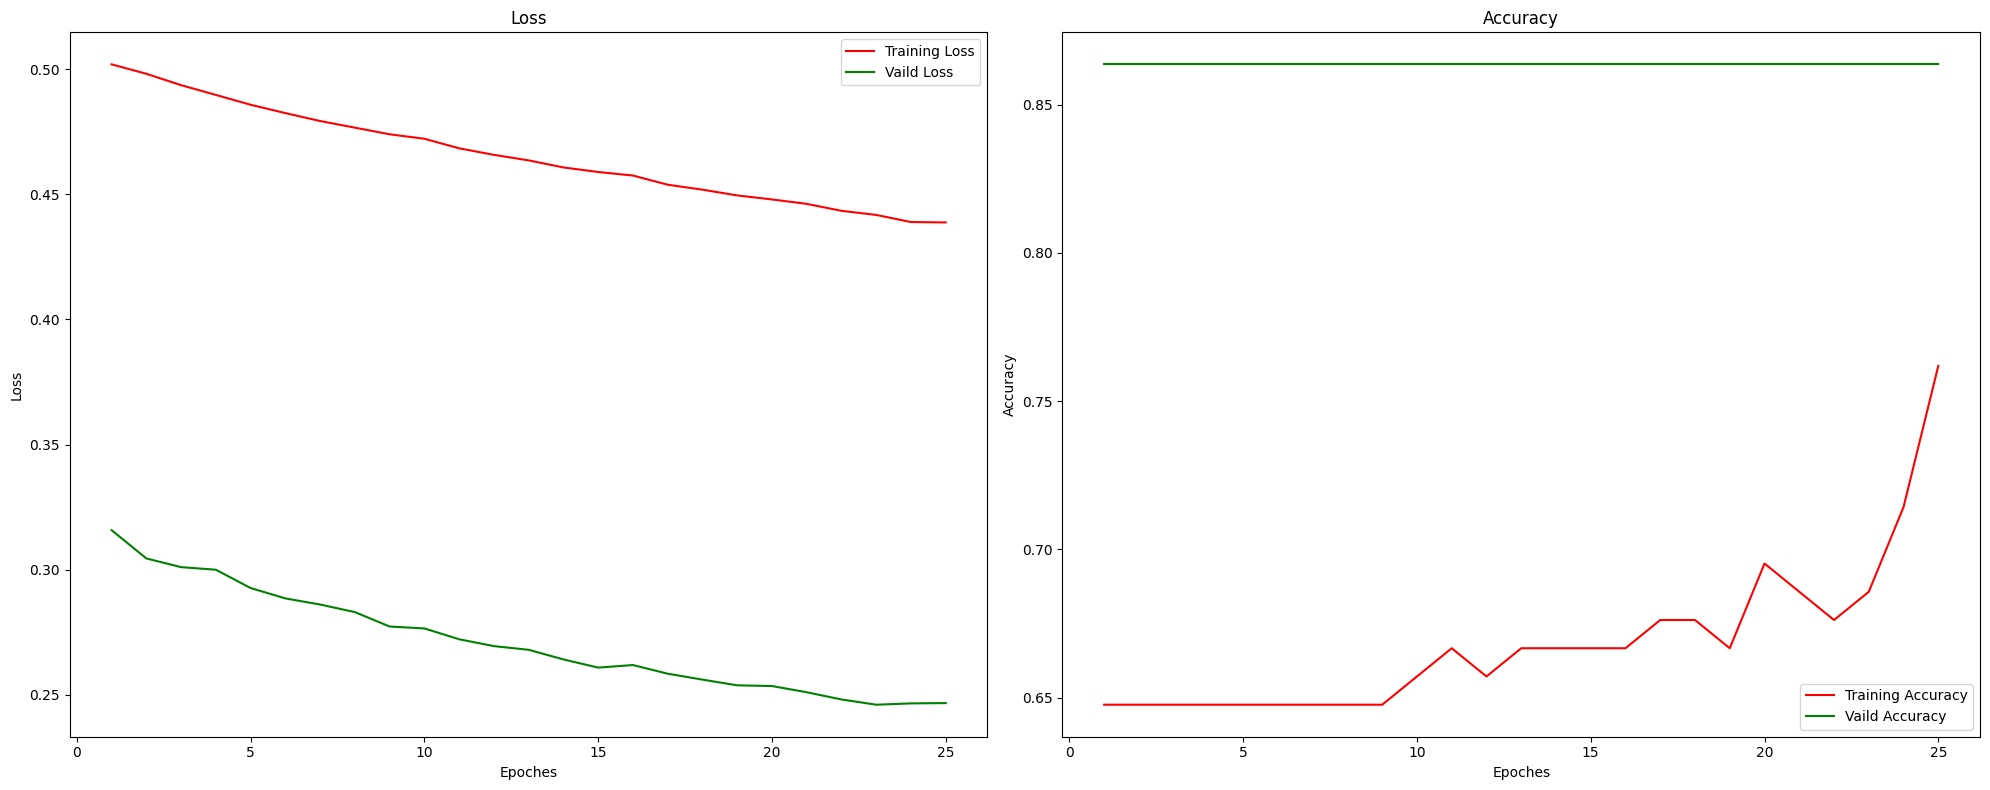

In [28]:
tr_acc = history.history['accuracy']
tr_loss = history.history['loss']
val_acc = history.history['val_accuracy']   
val_loss = history.history['val_loss']

epochhs  = [i+1 for i in range(len(tr_acc))]

plt.figure(figsize=(20, 8))
plt.subplot(1,2,1)
plt.plot(epochhs, tr_loss, 'r',label='Training Loss')
plt.plot(epochhs, val_loss, 'g',label='Vaild Loss')
plt.title('Loss')
plt.legend()
plt.xlabel('Epoches')
plt.ylabel('Loss')

plt.subplot(1,2,2)
plt.plot(epochhs, tr_acc, 'r',label='Training Accuracy')
plt.plot(epochhs, val_acc, 'g',label='Vaild Accuracy')
plt.title('Accuracy')
plt.legend()
plt.xlabel('Epoches')
plt.ylabel('Accuracy')

plt.tight_layout()
plt.show()

In [29]:
y_pred = model.predict(x_test)
print(y_pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
[[9.8921865e-01 1.4061824e-03 9.3751745e-03]
 [7.7967625e-04 3.7821472e-01 6.2100565e-01]
 [5.1559188e-04 3.6240184e-01 6.3708258e-01]
 [9.8754013e-01 1.7523172e-03 1.0707626e-02]
 [1.2206988e-03 3.9563954e-01 6.0313976e-01]
 [1.0484049e-02 4.7961718e-01 5.0989884e-01]
 [6.1538378e-03 4.5938617e-01 5.3445995e-01]
 [9.8892701e-01 1.4645761e-03 9.6084569e-03]
 [3.7402469e-03 4.3986043e-01 5.5639935e-01]
 [7.5252098e-03 4.6713865e-01 5.2533609e-01]
 [3.4302793e-02 5.1732534e-01 4.4837195e-01]
 [7.3449081e-04 3.7591508e-01 6.2335044e-01]
 [1.4247136e-02 4.9066848e-01 4.9508446e-01]
 [4.6136722e-04 3.5820243e-01 6.4133620e-01]
 [2.2135371e-02 5.0524700e-01 4.7261760e-01]
 [9.7721523e-01 4.3272423e-03 1.8457491e-02]
 [7.8687109e-03 4.6884269e-01 5.2328861e-01]
 [7.5436207e-03 4.6723214e-01 5.2522427e-01]
 [2.3293082e-02 5.0679964e-01 4.6990725e-01]
 [4.1478404e-04 3.5420120e-01 6.4538407e-01]
 [9.8300850e-01 2.7966716e-03 1.4194788e-02]
 [9.9033195e-01 1

In [30]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_pred_labels = np.argmax(y_pred, axis=1)
print(y_pred_labels)
print(accuracy_score(y_test, y_pred_labels))

[0 2 2 0 2 2 2 0 2 2 1 2 2 2 1 0 2 2 1 2 0 0 2]
0.6956521739130435


<Axes: >

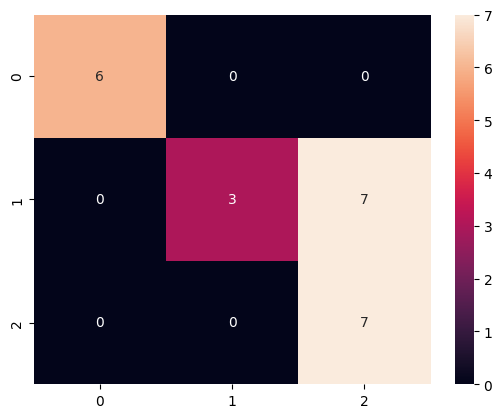

In [31]:
con = confusion_matrix(y_test, y_pred_labels)
sns.heatmap(con, annot = True)

In [34]:
model.save('iris_model.h5')

In [35]:
from tensorflow.keras.models import load_model
model = load_model('iris_model.h5')


In [36]:
sample = [[5.1, 3.5, 1.4, 0.2]]
pred = model.predict(np.array(sample))
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


array([[0.98370105, 0.00262758, 0.01367133]], dtype=float32)